# Projet Deep Learning — Prévision du cours boursier d'Apple et de Microsoft avec un LSTM

**Architecture choisie :** LSTM (famille 4 : LSTM / GRU).

**Dataset :** historique journalier des actions Apple (AAPL) et Microsoft (MSFT) du 02/01/2020 au 31/12/2021
(505 jours de cotation chacune). Source : Yahoo Finance
([AAPL](https://finance.yahoo.com/quote/AAPL/history), [MSFT](https://finance.yahoo.com/quote/MSFT/history)),
téléchargé avec la bibliothèque Python `yfinance`.

**Objectif :** à partir des 30 derniers jours de cotation, prédire le cours de clôture du jour suivant.

**Pourquoi un LSTM ?** Un cours de bourse est une série temporelle : la valeur d'un jour dépend des jours
précédents. Les LSTM sont des réseaux récurrents conçus pour mémoriser ces dépendances temporelles,
grâce à leurs portes (oubli, entrée, sortie) qui limitent le problème de disparition du gradient des RNN simples.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

TICKERS = {"AAPL": "Apple", "MSFT": "Microsoft"}
WINDOW = 30          # nombre de jours observés pour prédire le jour suivant
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15     # le reste (15 %) sert de jeu de test

## 1. Chargement et exploration des données

In [2]:
data = {
    t: pd.read_csv(DATA_DIR / f"{t}_2020_2021.csv", parse_dates=["Date"]).set_index("Date")
    for t in TICKERS
}
for t, df in data.items():
    print(f"=== {TICKERS[t]} ({t}) : {len(df)} jours, du {df.index.min():%d/%m/%Y} au {df.index.max():%d/%m/%Y}")
    print(df.describe().round(2), "\n")
    print("Valeurs manquantes :", int(df.isna().sum().sum()), "\n")

=== Apple (AAPL) : 505 jours, du 02/01/2020 au 31/12/2021
         Open    High     Low   Close  Adj Close        Volume
count  505.00  505.00  505.00  505.00     505.00  5.050000e+02
mean   118.02  119.46  116.65  118.12     114.68  1.241110e+08
std     29.46   29.59   29.27   29.44      28.98  6.315499e+07
min     57.02   57.12   53.15   56.09      54.08  4.100000e+07
25%     91.28   92.97   90.91   91.63      88.58  8.086110e+07
50%    123.75  125.18  122.21  123.75     120.23  1.088292e+08
75%    140.07  142.21  138.37  141.11     137.53  1.477512e+08
max    181.12  182.13  178.53  180.33     176.01  4.265100e+08 

Valeurs manquantes : 0 

=== Microsoft (MSFT) : 505 jours, du 02/01/2020 au 31/12/2021
         Open    High     Low   Close  Adj Close       Volume
count  505.00  505.00  505.00  505.00     505.00       505.00
mean   234.21  236.66  231.83  234.40     223.67  31847833.86
std     51.60   51.45   51.65   51.63      50.46  14475905.76
min    137.01  140.57  132.52  135.42 

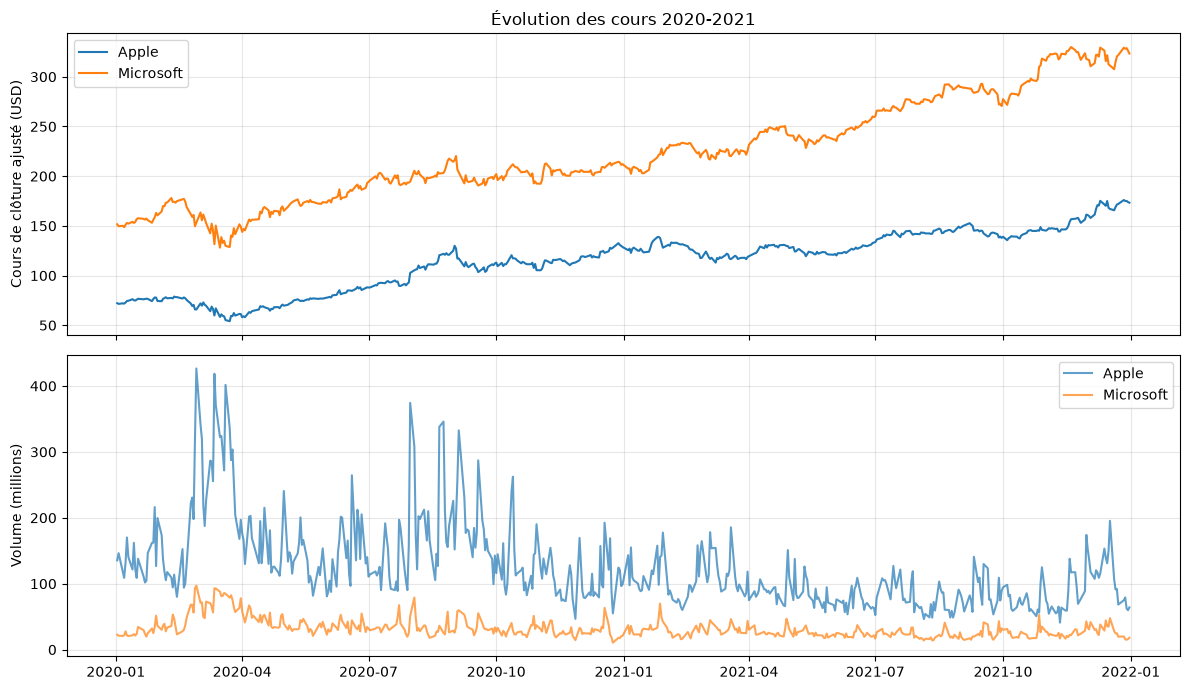

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for t, df in data.items():
    axes[0].plot(df.index, df["Adj Close"], label=TICKERS[t])
    axes[1].plot(df.index, df["Volume"] / 1e6, label=TICKERS[t], alpha=0.7)
axes[0].set_ylabel("Cours de clôture ajusté (USD)")
axes[0].set_title("Évolution des cours 2020-2021")
axes[1].set_ylabel("Volume (millions)")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "1_historique.png", dpi=120)
plt.show()

On observe le krach du Covid en mars 2020, puis une forte hausse continue jusqu'à fin 2021.
Conséquence importante : les prix de la fin de période (jeu de test) sont **plus élevés que tout ce que le modèle
aura vu à l'entraînement**. Un réseau entraîné directement sur les prix aurait du mal à extrapoler.
On va donc travailler sur des grandeurs **stationnaires** (rendements, variations relatives), puis reconstruire le prix.

## 2. Préparation des données

Pour chaque jour \(t\), on calcule 4 variables :
- `log_ret` : rendement logarithmique \(\ln(P_t / P_{t-1})\) du cours de clôture ajusté ;
- `hl_range` : amplitude de la journée \((High - Low) / Close\) ;
- `oc_ret` : variation intra-journalière \((Close - Open) / Open\) ;
- `log_vol` : variation du volume \(\ln(V_t / V_{t-1})\).

**Cible :** le rendement logarithmique du jour suivant. Le prix prédit est ensuite reconstruit par
\(\hat P_{t+1} = P_t \cdot e^{\hat r_{t+1}}\).

In [4]:
FEATURES = ["log_ret", "hl_range", "oc_ret", "log_vol"]


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=df.index)
    out["price"] = df["Adj Close"]
    out["log_ret"] = np.log(df["Adj Close"] / df["Adj Close"].shift(1))
    out["hl_range"] = (df["High"] - df["Low"]) / df["Close"]
    out["oc_ret"] = (df["Close"] - df["Open"]) / df["Open"]
    out["log_vol"] = np.log(df["Volume"] / df["Volume"].shift(1))
    return out.dropna()


def make_windows(feats: np.ndarray, log_ret: np.ndarray, window: int):
    """X[i] = jours [i, i+window), y[i] = rendement du jour i+window."""
    X, y = [], []
    for i in range(len(feats) - window):
        X.append(feats[i:i + window])
        y.append(log_ret[i + window])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


def prepare(df: pd.DataFrame):
    feats = build_features(df)
    n = len(feats)
    n_train = int(n * TRAIN_RATIO)
    n_val = int(n * VAL_RATIO)

    # Le scaler est ajusté uniquement sur la période d'entraînement (pas de fuite d'information du futur)
    scaler = StandardScaler().fit(feats[FEATURES].iloc[:n_train])
    scaled = scaler.transform(feats[FEATURES])
    ret_mean, ret_std = scaler.mean_[0], scaler.scale_[0]

    X, y = make_windows(scaled, scaled[:, 0], WINDOW)
    target_dates = feats.index[WINDOW:]
    prev_price = feats["price"].values[WINDOW - 1:-1]   # prix connu la veille de chaque cible
    true_price = feats["price"].values[WINDOW:]

    # Découpage chronologique : la cible de chaque fenêtre détermine son appartenance au jeu
    idx_train = np.arange(len(X)) < n_train - WINDOW
    idx_val = (~idx_train) & (np.arange(len(X)) < n_train + n_val - WINDOW)
    idx_test = ~(idx_train | idx_val)

    split = {}
    for name, m in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
        split[name] = dict(X=X[m], y=y[m], dates=target_dates[m],
                           prev_price=prev_price[m], true_price=true_price[m])
    return split, (ret_mean, ret_std)


prepared = {t: prepare(df) for t, df in data.items()}
for t, (split, _) in prepared.items():
    print(t, {k: v["X"].shape for k, v in split.items()})
    for k, v in split.items():
        print(f"   {k:5s}: {v['dates'].min():%d/%m/%Y} -> {v['dates'].max():%d/%m/%Y}")

AAPL {'train': (322, 30, 4), 'val': (75, 30, 4), 'test': (77, 30, 4)}
   train: 18/02/2020 -> 26/05/2021
   val  : 27/05/2021 -> 13/09/2021
   test : 14/09/2021 -> 31/12/2021
MSFT {'train': (322, 30, 4), 'val': (75, 30, 4), 'test': (77, 30, 4)}
   train: 18/02/2020 -> 26/05/2021
   val  : 27/05/2021 -> 13/09/2021
   test : 14/09/2021 -> 31/12/2021


## 3. Le modèle LSTM

- 2 couches LSTM empilées de 64 unités, avec dropout de 0,2 entre les couches ;
- une couche dense (fully connected) qui transforme le dernier état caché en une valeur : le rendement prédit.

In [5]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features: int, hidden: int = 64, layers: int = 2, dropout: float = 0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers, dropout=dropout, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, x):
        out, _ = self.lstm(x)              # out : (batch, window, hidden)
        return self.head(out[:, -1]).squeeze(-1)


print(LSTMForecaster(len(FEATURES)))
print("Nombre de paramètres :", sum(p.numel() for p in LSTMForecaster(len(FEATURES)).parameters()))

LSTMForecaster(
  (lstm): LSTM(4, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=64, out_features=1, bias=True)
  )
)
Nombre de paramètres : 51265


## 4. Entraînement

- Fonction de perte : erreur quadratique moyenne (MSE) ;
- Optimiseur : Adam (taux d'apprentissage 0,001) ;
- Lots de 32 fenêtres, jusqu'à 150 époques ;
- **Early stopping** : on arrête quand la perte de validation ne s'améliore plus pendant 20 époques,
  et on garde les poids de la meilleure époque (limite le surapprentissage, important avec peu de données).

In [6]:
def train_model(split, epochs=150, batch_size=32, lr=1e-3, patience=20):
    torch.manual_seed(SEED)
    model = LSTMForecaster(len(FEATURES))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    Xtr, ytr = torch.tensor(split["train"]["X"]), torch.tensor(split["train"]["y"])
    Xva, yva = torch.tensor(split["val"]["X"]), torch.tensor(split["val"]["y"])

    history = {"train": [], "val": []}
    best_val, best_state, wait = float("inf"), None, 0
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        total = 0.0
        for i in range(0, len(Xtr), batch_size):
            b = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[b]), ytr[b])
            loss.backward()
            opt.step()
            total += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xva), yva).item()
        history["train"].append(total / len(Xtr))
        history["val"].append(val_loss)

        if val_loss < best_val:
            best_val, wait = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    best_epoch = int(np.argmin(history["val"])) + 1
    print(f"Arrêt à l'époque {epoch + 1}, meilleure époque : {best_epoch} (val MSE = {best_val:.4f})")
    return model, history


models, histories = {}, {}
for t, (split, _) in prepared.items():
    print(f"--- {TICKERS[t]}")
    models[t], histories[t] = train_model(split)

--- Apple


Arrêt à l'époque 28, meilleure époque : 8 (val MSE = 0.1973)
--- Microsoft


Arrêt à l'époque 21, meilleure époque : 1 (val MSE = 0.1187)


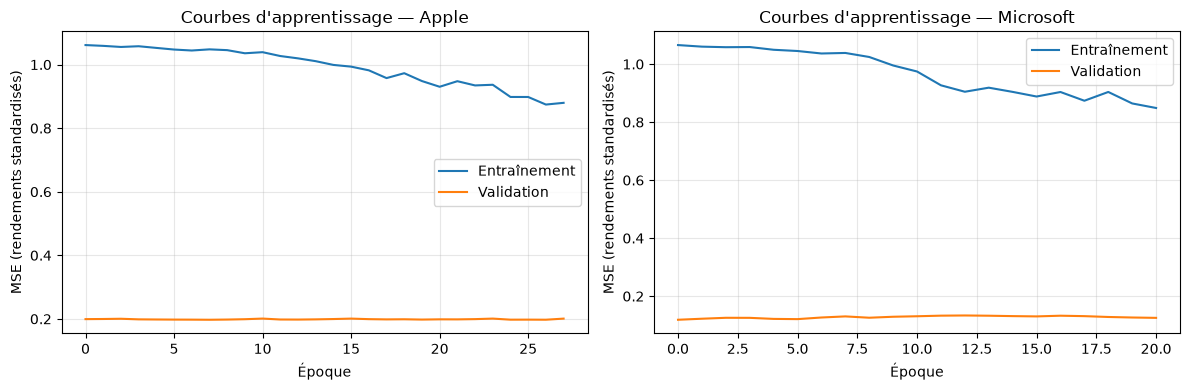

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, t in zip(axes, TICKERS):
    ax.plot(histories[t]["train"], label="Entraînement")
    ax.plot(histories[t]["val"], label="Validation")
    ax.set_title(f"Courbes d'apprentissage — {TICKERS[t]}")
    ax.set_xlabel("Époque")
    ax.set_ylabel("MSE (rendements standardisés)")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "2_courbes_apprentissage.png", dpi=120)
plt.show()

**Lecture des courbes :** la perte d'entraînement diminue, mais la perte de validation reste plate : le modèle apprend
des particularités de la période d'entraînement qui ne se généralisent pas (début de surapprentissage),
d'où l'arrêt anticipé après quelques époques.
La perte de validation est plus basse que celle d'entraînement car la période de validation (été 2021) a été
beaucoup plus calme que la période d'entraînement, qui contient le krach du Covid de mars 2020 :
des rendements plus petits donnent mécaniquement une MSE plus petite.

## 5. Évaluation sur le jeu de test

On compare le LSTM à un **modèle naïf** (« demain = aujourd'hui », c'est-à-dire rendement prédit nul).
C'est la référence classique en finance : un modèle de prévision n'est utile que s'il fait mieux que lui.

Métriques :
- RMSE, MAE (en dollars) et MAPE (en %) sur le prix reconstruit ;
- **précision directionnelle** : pourcentage de jours où le modèle prédit correctement si le cours monte ou baisse.

In [8]:
def evaluate(model, part, ret_stats):
    ret_mean, ret_std = ret_stats
    model.eval()
    with torch.no_grad():
        pred_scaled = model(torch.tensor(part["X"])).numpy()
    pred_ret = pred_scaled * ret_std + ret_mean
    true_ret = part["y"] * ret_std + ret_mean
    pred_price = part["prev_price"] * np.exp(pred_ret)
    return pred_ret, true_ret, pred_price


def metrics(true_price, pred_price, true_ret=None, pred_ret=None):
    res = {
        "RMSE ($)": np.sqrt(mean_squared_error(true_price, pred_price)),
        "MAE ($)": mean_absolute_error(true_price, pred_price),
        "MAPE (%)": np.mean(np.abs((true_price - pred_price) / true_price)) * 100,
    }
    res["Précision directionnelle (%)"] = (
        np.mean(np.sign(pred_ret) == np.sign(true_ret)) * 100 if pred_ret is not None else np.nan
    )
    return res


rows, preds = [], {}
for t, (split, stats) in prepared.items():
    test = split["test"]
    pred_ret, true_ret, pred_price = evaluate(models[t], test, stats)
    preds[t] = pred_price
    rows.append({"Action": t, "Modèle": "LSTM", **metrics(test["true_price"], pred_price, true_ret, pred_ret)})
    rows.append({"Action": t, "Modèle": "Naïf (P_t+1 = P_t)", **metrics(test["true_price"], test["prev_price"])})
    up_share = np.mean(true_ret > 0) * 100
    print(f"{t} : part de jours en hausse dans le test = {up_share:.1f} %")

results = pd.DataFrame(rows).set_index(["Action", "Modèle"]).round(2)
results.to_csv("resultats.csv")
results

AAPL : part de jours en hausse dans le test = 55.8 %
MSFT : part de jours en hausse dans le test = 57.1 %


RMSE ($)  MAE ($)  MAPE (%)  \
Action Modèle                                            
AAPL   LSTM                    2.33     1.76      1.14   
       Naïf (P_t+1 = P_t)      2.34     1.77      1.14   
MSFT   LSTM                    4.41     3.34      1.09   
       Naïf (P_t+1 = P_t)      4.44     3.36      1.10   

                           Précision directionnelle (%)  
Action Modèle                                            
AAPL   LSTM                                       54.55  
       Naïf (P_t+1 = P_t)                           NaN  
MSFT   LSTM                                       57.14  
       Naïf (P_t+1 = P_t)                           NaN

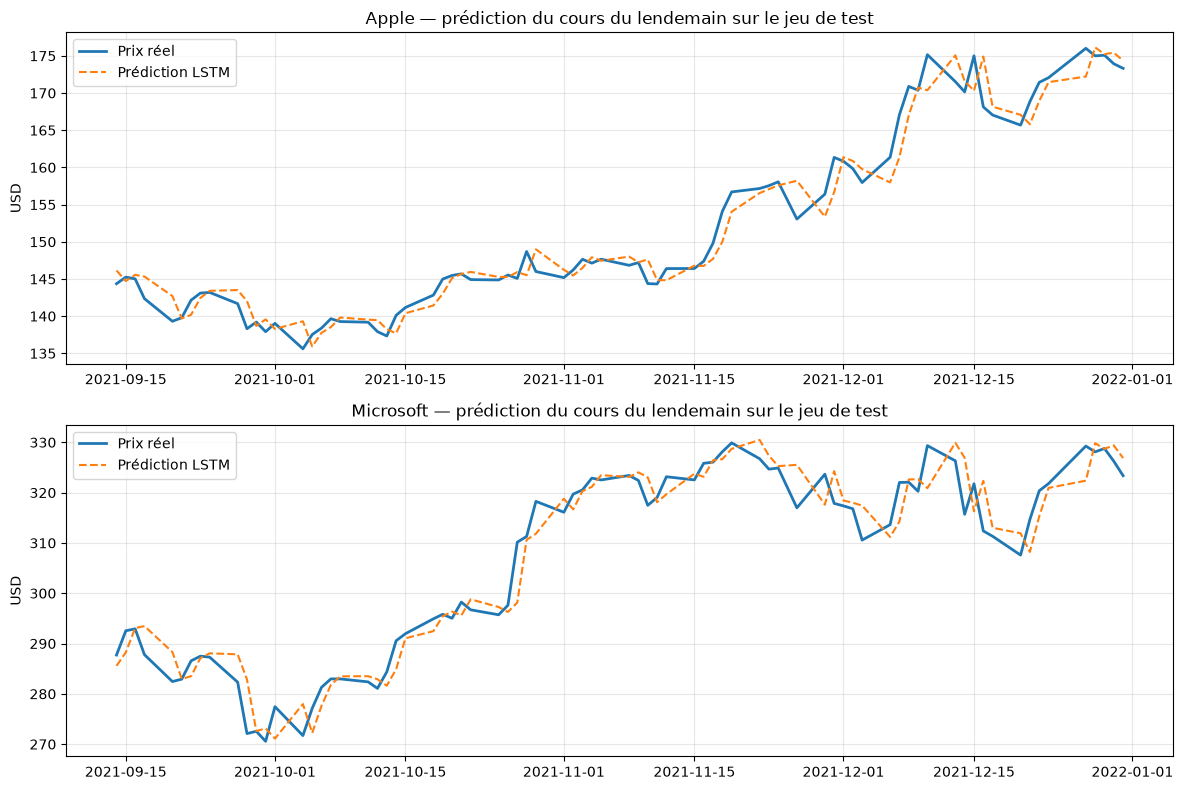

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, t in zip(axes, TICKERS):
    test = prepared[t][0]["test"]
    ax.plot(test["dates"], test["true_price"], label="Prix réel", lw=2)
    ax.plot(test["dates"], preds[t], label="Prédiction LSTM", ls="--")
    ax.set_title(f"{TICKERS[t]} — prédiction du cours du lendemain sur le jeu de test")
    ax.set_ylabel("USD")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "3_predictions_test.png", dpi=120)
plt.show()

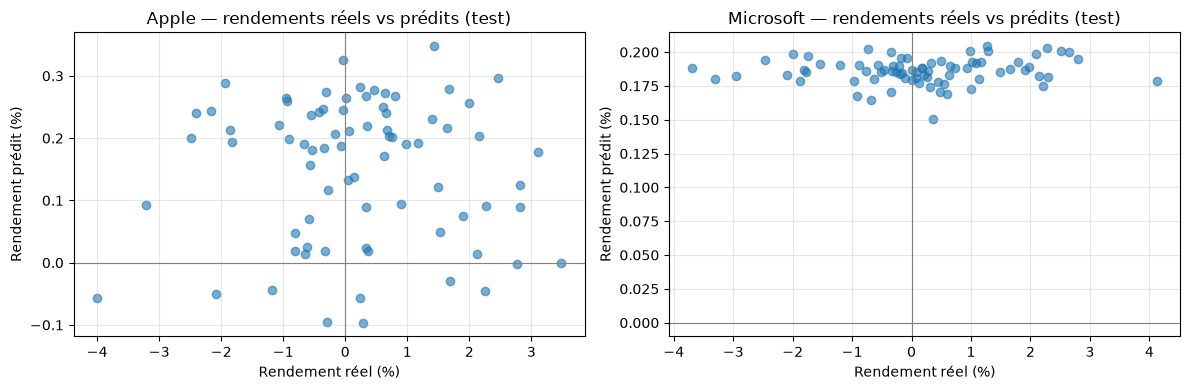

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, t in zip(axes, TICKERS):
    split, stats = prepared[t]
    pred_ret, true_ret, _ = evaluate(models[t], split["test"], stats)
    ax.scatter(true_ret * 100, pred_ret * 100, alpha=0.6)
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{TICKERS[t]} — rendements réels vs prédits (test)")
    ax.set_xlabel("Rendement réel (%)")
    ax.set_ylabel("Rendement prédit (%)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "4_rendements_test.png", dpi=120)
plt.show()

## 6. Conclusion

- Le LSTM suit très bien la courbe du prix réel et obtient une erreur relative (MAPE) de l'ordre de 1 %.
- **Mais** le modèle naïf « demain = aujourd'hui » obtient une erreur du même ordre : la qualité visuelle de la
  courbe vient surtout du fait que le prix de la veille est déjà connu. La vraie difficulté est de prédire
  la **variation** du lendemain, et les rendements prédits par le LSTM restent proches de zéro (graphique 4).
- La précision directionnelle (environ 55 %) est à peine supérieure, voire égale, à la part de jours en hausse
  dans le test (environ 56 %) : un modèle qui répondrait « ça monte » tous les jours ferait aussi bien.
- Ce résultat est cohérent avec l'**hypothèse d'efficience des marchés** : les variations journalières d'une action
  très liquide comme Apple ou Microsoft sont quasiment imprévisibles à partir de leur seul historique.
- Limites : peu de données (505 jours par action), une seule source d'information (les prix et volumes).

**Pistes d'amélioration :** allonger l'historique (10 ans au lieu de 2), ajouter des variables externes
(indice S&P 500, taux d'intérêt, sentiment des actualités), comparer avec un GRU ou un Transformer,
ou prédire un horizon plus long (tendance à 5 ou 20 jours).